In [146]:
import re
import torch
import numpy as np
import pandas as pd
import string
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

def get_roc_auc(scores, labels, dataset="CoQA"):
    if dataset in ["MMLU", "GSM8k"]:
        threshold = 0.3
    elif dataset in ["CoQA", "TriviaQA"]:
        threshold = 0.3
    elif dataset in ["SamSum", "XSUM"]:
        threshold = 0.3
    else:
        threshold = 0.80
    labels = (np.array(labels) < threshold).astype(int)
    return roc_auc_score(labels, scores)

        
def preproc_method_name(x):
    return x

def get_table_short(path, metric_names=['AlignScore'], dataset="CoQA", ue_metric="prr_0.5_normalized", level="sequence"):
    
    df = {}

    if isinstance(path, list):
        for i, p in enumerate(path):
            man = torch.load(p, weights_only=False)
            methods = np.unique([x[1] for x in man['metrics'].keys() if "2side" not in x[1]])

            for method in methods:
                if method in df and i > 0:
                    continue
                for metric in metric_names:
                    if ue_metric == "prr_0.5_normalized":
                        key = (level, method, metric, ue_metric)
                        scores = df.get(method, [])
                        scores.append(man['metrics'][key])
                    else:
                        metrics = np.array(man['gen_metrics'][(level, metric)])
                        uq = np.array([x if not isinstance(x, complex) else x.real for x in man['estimations'][(level, method)]])
                        scores = df.get(method, [])
                        isnan = np.isnan(uq)
                        if np.any(isnan):
                            print(f"Warning: NaN values in uncertainty scores for method {method}, metric {metric}. Replacing with min finite value. {np.sum(isnan)} NaN values found for method {method}.")
                            if np.all(isnan):
                                print(f"Error: All values are NaN for method {method}, metric {metric}. Cannot compute ROC AUC.")
                                uq[isnan] = 0.0
                            else:
                                uq[isnan] = np.nanmin(uq[~isnan])
                        isinf = np.isinf(uq)
                        if np.any(isinf):
                            print(f"Warning: Inf values in uncertainty scores for method {method}, metric {metric}. Replacing with max finite value. {np.sum(isinf)} Inf values found for method {method}.")
                            if np.all(isinf):
                                print(f"Error: All values are Inf for method {method}, metric {metric}. Cannot compute ROC AUC.")
                                uq[isinf] = 0.0
                            else:
                                uq[isinf] = np.nanmax(uq[~isinf])
                        scores.append(get_roc_auc(uq, metrics, dataset=dataset))
                    df[method] = scores
    else:
        man = torch.load(path, weights_only=False)
        methods = np.unique([x[1] for x in man['metrics'].keys() if "2side" not in x[1]])

        for method in methods:
            for metric in metric_names:
                if ue_metric == "prr_0.5_normalized":
                    key = (level, method, metric, ue_metric)
                    scores = df.get(method, [])
                    scores.append(man['metrics'][key])
                else:
                    metrics = np.array(man['gen_metrics'][(level, metric)])
                    uq = np.array([x if not isinstance(x, complex) else x.real for x in man['estimations'][(level, method)]])
                    scores = df.get(method, [])
                    isnan = np.isnan(uq)
                    if np.any(isnan):
                        print(f"Warning: NaN values in uncertainty scores for method {method}, metric {metric}. Replacing with min finite value. {np.sum(isnan)} NaN values found for method {method}.")
                        if np.all(isnan):
                            print(f"Error: All values are NaN for method {method}, metric {metric}. Cannot compute ROC AUC.")
                            uq[isnan] = 0.0
                        else:
                            uq[isnan] = np.nanmin(uq[~isnan])
                    isinf = np.isinf(uq)
                    if np.any(isinf):
                        print(f"Warning: Inf values in uncertainty scores for method {method}, metric {metric}. Replacing with max finite value. {np.sum(isinf)} Inf values found for method {method}.")
                        if np.all(isinf):
                            print(f"Error: All values are Inf for method {method}, metric {metric}. Cannot compute ROC AUC.")
                            uq[isinf] = 0.0
                        else:
                            uq[isinf] = np.nanmax(uq[~isinf])
                    scores.append(get_roc_auc(uq, metrics, dataset=dataset))
                df[method] = scores

    df0 = pd.DataFrame(df, index=pd.MultiIndex.from_tuples([(dataset, m) for m in metric_names])).T
    df0.loc[:, (dataset, 'Method')] = [x for x in df0.index]
    return df0.reset_index(drop=True)

# LLaDa-1.5

In [147]:
import os
import copy
from scipy.stats import rankdata

base_path = "./workdir/output_dllm_dec25_maskedll_final"

datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        # "SamSum": "../workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-25/01-04-55/ue_manager_seed1",
        # "XSUM": "../workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-03-25/16-52-38/ue_manager_seed1",
        # "WMT14": "../workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-25/04-09-53/ue_manager_seed1",
        # "WMT19": "../workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-25/08-14-48/ue_manager_seed1",
        # "CoQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-10/21-58-20/ue_manager_seed1",
        # "GSM8k": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-03-24/14-28-05/ue_manager_seed1",
        # "MMLU": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-03-25/15-16-53/ue_manager_seed1",
        # "TriviaQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-11/00-58-13/ue_manager_seed1",

        # "TruthfulQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-11/03-32-27/ue_manager_seed1",

        # "SamSum": "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1",
        # "GSM8k": "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-19/15-37-54/ue_manager_seed1",
        # "CoQA": "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-27/14-18-55/ue_manager_seed1",
        # "TriviaQA": "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-27/19-07-35/ue_manager_seed1",
        # "MMLU": "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-27/17-29-11/ue_manager_seed1",
        # "WMT14": "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1",
        # "WMT19": "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-27/21-24-12/ue_manager_seed1",
        # "XSUM": "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1",    

        # "SamSum": "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1",
        # "GSM8k": "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-29/02-02-10/ue_manager_seed1",
        # "CoQA": "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-28/22-17-01/ue_manager_seed1",
        # "TriviaQA": "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-29/00-32-16/ue_manager_seed1",
        # "MMLU": "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-28/23-42-57/ue_manager_seed1",
        # "WMT14": "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1",
        # "WMT19": "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-29/10-37-01/ue_manager_seed1",
        # "XSUM": "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1",   

        "SamSum": [
            "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"
        ],
        "GSM8k": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-19/15-37-54/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-29/02-02-10/ue_manager_seed1"
        ],
        "CoQA": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-27/14-18-55/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-28/22-17-01/ue_manager_seed1"
        ],
        "TriviaQA": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-27/19-07-35/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-29/00-32-16/ue_manager_seed1"
        ],
        "MMLU": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-27/17-29-11/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-28/23-42-57/ue_manager_seed1"
        ],
        "WMT14": [
            "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"
        ],
        "WMT19": [
            "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-27/21-24-12/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-29/10-37-01/ue_manager_seed1"
        ],
        "XSUM": [
            "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"
        ],
 
    }
}

filename = "ue_manager_seed1"
dfs = {}

all_paths = []
for model in models:
    dfs[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        task = ds.split("/")[0]
        ds = '/'.join(ds.split("/")[1:])
        path = f"{base_path}/{task}/{model}/{ds}/"
        final_path = None
        if model in paths.keys() and ds_name in paths[model].keys():
            final_path = paths[model][ds_name]
        else:
            continue
        if final_path is not None:
            print(final_path)
            all_paths.append(final_path)
            if task == "ats":
                metric_names=['AlignScore']
            elif (ds_name in ["MMLU", "GSM8k"]):
                metric_names=["Accuracy"]
            elif task == "qa":
                metric_names=['AlignScore']
            elif task == "nmt":
                metric_names=['Comet']
            df = get_table_short(final_path, dataset=ds_name, metric_names=metric_names, ue_metric="roc_auc", level="sequence")
            dfs[model][ds_name] = df.reset_index(drop=True)

["../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_si

In [148]:
dfs_short_new = []
methods = None
model = models[0]

for key in dfs[model].keys():
    df_ = dfs[model][key]   
    if methods is None:
        methods = df_[df_.columns[-1]]
        # methods = [m for m in methods if "CocoaMCMaskedNLL" in m]
        # methods = [m for m in methods if "DebertaContra" not in m]
        # methods = [m for m in methods if "InverseProgress" not in m]
        # methods = [m for m in methods if "BlockMax" not in m]
    df_ = df_.set_index(df_.columns[-1], drop=False).reindex(methods)
    
    if len(dfs_short_new):
        dfs_short_new.append(df_[df_.columns[[0]]])
    else:
        dfs_short_new.append(df_[df_.columns[[1, 0]]])
dfs_short_new = pd.concat(dfs_short_new, axis=1).reset_index(drop=True)
# dfs_short_new.loc[:, ('', "Mean")] = dfs_short_new[dfs_short_new.columns[1:]].mean(axis=1)
# dfs_short_new.loc[:, ('', "Mean Rank")] = dfs_short_new[dfs_short_new.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [149]:
# dfs_short_new.sort_values(dfs_short_new.columns[-2], ascending=False).style.background_gradient(axis=0)

In [150]:
paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "SamSum": "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
        "WMT14": "../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1",
        "WMT19": "../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1",
        "TriviaQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1",
        "CoQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1",
        # "TruthfulQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-07/06-40-05/ue_manager_seed1",
        "MMLU": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1",
        "XSUM": "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1",
        "GSM8k": ["../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-31/ue_manager_seed1",
                  "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-29/ue_manager_seed1"],
    }
}


filename = "ue_manager_seed1"
dfs = {}

all_paths = []
for model in models:
    dfs[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        task = ds.split("/")[0]
        ds = '/'.join(ds.split("/")[1:])
        path = f"{base_path}/{task}/{model}/{ds}/"
        final_path = None
        if model in paths.keys() and ds_name in paths[model].keys():
            final_path = paths[model][ds_name]
        else:
            continue
        if final_path is not None:
            print(final_path)
            all_paths.append(final_path)
            if task == "ats":
                metric_names=['AlignScore']
            elif (ds_name in ["MMLU", "GSM8k"]):
                metric_names=["Accuracy"]
            elif task == "qa":
                metric_names=['AlignScore']
            elif task == "nmt":
                metric_names=['Comet']
            df = get_table_short(final_path, dataset=ds_name, metric_names=metric_names, ue_metric="roc_auc", level="sequence")
            dfs[model][ds_name] = df.reset_index(drop=True)

../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1
../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1
../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1
../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1
Error: All values are Inf for method KernelLanguageEntropyTrace, metric Accuracy. Cannot compute ROC AU

In [151]:
dfs_short = []
methods = None
model = models[0]

for key in dfs[model].keys():
    df_ = dfs[model][key]   
    if methods is None:
        methods = df_[df_.columns[-1]]
        # methods = [m for m in methods if "FullTrace" in m]
        # methods = [m for m in methods if "InverseProgress" not in m]
    df_ = df_.set_index(df_.columns[-1], drop=False).reindex(methods)
    
    if len(dfs_short):
        dfs_short.append(df_[df_.columns[[0]]])
    else:
        dfs_short.append(df_[df_.columns[[1, 0]]])
dfs_short = pd.concat(dfs_short, axis=1).reset_index(drop=True)
# dfs_short.loc[:, ('', "Mean")] = dfs_short[dfs_short.columns[1:]].mean(axis=1)
# dfs_short.loc[:, ('', "Mean Rank")] = dfs_short[dfs_short.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [152]:
df_all = pd.concat([dfs_short, dfs_short_new], axis=0).reset_index(drop=True)
df_all.loc[:, ('', "Mean")] = df_all[df_all.columns[1:]].mean(axis=1)
# df_all.loc[:, ('', "Mean Rank")] = df_all[df_all.columns[1:-1]].apply(lambda x: rankdata(-x)).mean(axis=1).round(2)

In [153]:
# df_all.iloc[[589, 593, 594, 595, 591, 235, 145]].sort_values(df_all.columns[-1], ascending=False).style.background_gradient(axis=0)

In [154]:
df_all.sort_values(df_all.columns[-1], ascending=False).style.background_gradient(axis=0) #CocoaMCMaskedNLLCrossEncoderFullTraceNFE

In [155]:
import matplotlib 
from matplotlib import colors
import matplotlib.pyplot as plt 

cmap = matplotlib.cm.get_cmap('coolwarm_r')#'Greens')
my_cmap = cmap(np.arange(cmap.N))
my_cmap[:,-1] = 0.5
my_cmap = colors.ListedColormap(my_cmap)

def b_g(s, cmap, low=0, high=0):
    values = s.apply(lambda x: float(x.split("±")[0]) if len(x.split("±"))>1 else x)
    if isinstance(values.max(), str):
        return ['' for c in values]
    rng = values.max() - values.min()
    norm = colors.Normalize(values.min() - (rng * low), values.max() + (rng * high))
    normed = norm(values.values)
    back_colors = [colors.rgb2hex(x) for x in plt.cm.get_cmap(cmap)(normed)]
    text_colors = ["white" if x>0.3 else "black" for x in normed]
    return [f'color: {text_color}; background-color: {color}' for text_color, color in zip(text_colors, back_colors)]

def rgba2rgb(rgba, background=(1,1,1)):
    ch = rgba.shape[0]
    if ch == 3:
        return rgba

    assert ch == 4, 'RGBA image has 4 channels.'

    r, g, b, a = rgba[0], rgba[1], rgba[2], rgba[3]
    a = np.asarray(a, dtype='float32')
    R, G, B = background

    r_new = r * a + (1.0 - a) * R
    g_new = g * a + (1.0 - a) * G
    b_new = b * a + (1.0 - a) * B

    return [r_new, g_new, b_new]


def to_color(text, vals):
    vals = rgba2rgb(np.array(vals))
    return '\\cellcolor[rgb]{'+f'{vals[0]},'+f'{vals[1]},'+f'{vals[2]}'+'} '+f'{text:.2f}'

def bold_best(df, columns):
    for col in columns:
        values_init_raw = [float(x) if x!='-' else np.nan for x in df[col]]
        values_init = np.array([float(x) for x in df[col] if x!='-'])
        if values_init.min() != values_init.max():
            values_init_raw = np.array([(x - values_init.min()) / (values_init.max() - values_init.min()) if not np.isnan(x) else x for x in values_init_raw])
            
        def get_new_x(x):
            if isinstance(x, str):
                return x
            return '-'
        values = [to_color(raw, my_cmap(1-float(x))) if (isinstance(x, float) and (not np.isnan(x))) else get_new_x(x) for raw, x in zip(df[col], values_init_raw)]
        df[col] = values
    return df

def prepare_latex(df1, s=2):
    start_tex = '\\begin{table*}[!ht] \\resizebox{\\textwidth}{!}{'
    end_tex = "}\\caption{\\label{tab:mistral_results} PRR$\\uparrow$ for Mistral 7b v0.2 model for various tasks for the considered sequence-level methods. Darker color indicates better results.}\end{table*}"
    df1 = bold_best(df1, df1.columns[s:])
    latex_table = df1.to_latex(bold_rows=False, index=False).replace('±', '$\pm$')
        
    latex_table = latex_table.replace('\\textbackslash ', '\\')
    latex_table = latex_table.replace('{lllllllllllllllllllll}', '{ll||cc|cc|cc|cc|cc|cc|cc|cc|cc|c}')
    latex_table = latex_table.replace('{llllllllllllllllllll}', '{l||cc|cc|cc|cc|cc|cc|cc|cc|cc|c}')
    latex_table = latex_table.replace('{lllllllllllllll}', '{ll||cc|cc|cc|cc|cc|cc|c}')
    latex_table = latex_table.replace('{lllllllll}', '{ll||cc|cc|cc|c}')
    latex_table = latex_table.replace('{llllllll}', '{l|c|c|c|c|c|c|c}')
    latex_table = latex_table.replace('{llllllllll}', '{l|c|c|c|c|c|c|c|c|c}')

    
    latex_table = latex_table.replace('mean', '$\\frac{1}{K}\\sum_{k=1}^K p_k$')
    latex_table = latex_table.replace('sum(log(p_i))', '$\\sum_{k=1}^K \\log p_k$')

    latex_table = latex_table.replace('\\{', '{')
    latex_table = latex_table.replace('\\}', '}')
    str_list = latex_table.split('\n')
    str_list.pop(3)
    latex_table = '\n'.join(str_list)
    return start_tex+latex_table+end_tex

/tmp/ipykernel_2726786/3824649416.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = matplotlib.cm.get_cmap('coolwarm_r')#'Greens')


### Results with baseline

In [156]:
df_all_selected = df_all.iloc[[47,
                               68, 7,
                               30,
                               77,
                               564, 569, 118, 537, 4, 5,
                               235, 589]]
df_all_selected[df_all_selected.columns[0]] = df_all_selected[df_all_selected.columns[0]].replace({"MaximumSequenceProbability": "MSP", "ConfidenceAtCommit_avg": "CommitNLL", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G", "KernelLanguageEntropy": "KLE", "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCNLL-Norm", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", "EigenScore": "EigenScore", "LUQ": "LUQ", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L"})
df_all_selected.style.background_gradient(axis=0)

## Time

In [157]:
def get_time(path, base=False):
    methods_diff = {
        "MSP": ["MaximumSequenceProbability"],
        "NFE": ["NFEUncertainty"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "CommitNLL": ["ConfidenceAtCommit_avg"],
        # "TraceEntropy": ["TraceEntropy_avg"],
        "AD-Full": ["AvgDissimilarityFullTrace", "greedy_sentence_similarity_full_trace"],
        "D-CoCoA-G": ["CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "greedy_sentence_similarity_full_trace", "mc_masked_ll"],
        "D-CoCoA-L": ["CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace", "greedy_sentence_similarity_block"],
    }
    methods_base = {
        "MSP": ["MaximumSequenceProbability"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "KLE": ["KernelLanguageEntropy", "semantic_matrix_entail", "sample_texts"],
        # "DegMat": ["DegMat_NLI_score_entail", "semantic_matrix_entail", "sample_texts"],
        # "LUQ": ["LUQ", "semantic_matrix_entail_logits", "sample_texts"],
        "CoCoA-MTE": ["CocoaMTE", "greedy_sentence_similarity", "sample_texts"],
        # "EigenScore": ["EigenScore", "sample_embeddings"],
        "CoCoA-MCNLL": ["CocoaMCMaskedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_ll"],
        "CoCoA-MCNLL-Norm" : ["CocoaMCMaskedNormalizedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_normalized_ll"],
        "TAD": ["TAD", "attention_all"],
        "SAR": ["SAR", "sample_sentence_similarity", "sample_texts"],
        # "SemanticEntropy": ["SemanticEntropy", "sample_texts", "semantic_matrix_entail", "semantic_classes_entail"],
    }

    times = {}
    seen_stats = {}
    
    if isinstance(path, list):
        for p in path:
            man = torch.load(p, weights_only=False)
            if base:
                methods = methods_base
            else:
                methods = methods_diff
            
            for method in methods.keys():
                for stat in methods[method]:
                    if method in seen_stats.keys() and stat in seen_stats[method]:
                        # print("seen", method, stat)
                        continue
                    if stat is None:
                        times[method] = 0
                        continue
                    if methods[method][0] not in man["time_stats"].keys():
                        # times[method] = 0
                        continue
                    elif method not in times.keys():
                        times[method] = 0
                    # print(method, stat)
                    scores = np.array(man["time_stats"][stat])
                    seen_stats[method] = seen_stats.get(method, set()).union(set([stat]))
                    if len(scores) == 0:
                        print(stat, scores)
                        # print(seen_stats)
                    times[method] += np.array(scores[1:])
    else:
        man = torch.load(path, weights_only=False)
        if base:
            methods = methods_base
        else:
            methods = methods_diff
        
        for method in methods.keys():
            times[method] = 0
            for stat in methods[method]:
                if stat is None:
                    times[method] = 0
                    continue
                scores = np.array(man["time_stats"][stat])
                if len(scores) == 0:
                    print(stat, scores)
                times[method] += np.array(scores[1:])
    return times

In [158]:
datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        # "SamSum": "../workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-25/01-04-55/ue_manager_seed1",
        # "XSUM": "../workdir/output_dllm_dec25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-03-25/16-52-38/ue_manager_seed1",
        # "WMT14": "../workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-25/04-09-53/ue_manager_seed1",
        # "WMT19": "../workdir/output_dllm_dec25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-25/08-14-48/ue_manager_seed1",
        # "CoQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-10/21-58-20/ue_manager_seed1",
        # "GSM8k": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-03-24/14-28-05/ue_manager_seed1",
        # "MMLU": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-03-25/15-16-53/ue_manager_seed1",
        # "TriviaQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-11/00-58-13/ue_manager_seed1",
        # "TruthfulQA": "../workdir/output_dllm_dec25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-11/03-32-27/ue_manager_seed1",

        "SamSum": [
            "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"
        ],
        "GSM8k": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-19/15-37-54/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-29/02-02-10/ue_manager_seed1"
        ],
        "CoQA": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-27/14-18-55/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-04-28/22-17-01/ue_manager_seed1"
        ],
        "TriviaQA": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-27/19-07-35/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-04-29/00-32-16/ue_manager_seed1"
        ],
        "MMLU": [
            "../workdir/output_dllm_apr25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-27/17-29-11/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-28/23-42-57/ue_manager_seed1"
        ],
        "WMT14": [
            "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"
        ],
        "WMT19": [
            "../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-27/21-24-12/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-04-29/10-37-01/ue_manager_seed1"
        ],
        "XSUM": [
            "../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1",
            "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"
        ],
        
    }
}

dfs_time = {}
all_paths = []
for model in models:
    dfs_time[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        try:
            final_path = paths[model][ds_name]
        except:
            continue
        if final_path is not None:
            print(final_path)
            df = get_time(final_path, base=False)
            dfs_time[model][ds_name] = df


["../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-27/21-29-08/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-29/07-56-42/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-27/14-32-23/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-04-29/05-31-48/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-27/14-52-55/ue_manager_seed1", "../workdir/output_dllm_may25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-04-29/03-09-38/ue_manager_seed1"]
["../workdir/output_dllm_apr25_maskedll_final/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_si

In [159]:
methods_time = {ds: {} for ds in dfs_time[model].keys()}
for ds in dfs_time[model]:
    for m in dfs_time[model][ds].keys():
        methods_time[ds][m] = np.mean(dfs_time[model][ds][m])

In [160]:
datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "SamSum": "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
        "WMT14": "../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1",
        "WMT19": "../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1",
        "TriviaQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1",
        "CoQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1",
        # "TruthfulQA": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/truthfulqa', 'simple_instruct']/2026-04-07/06-40-05/ue_manager_seed1",
        "MMLU": "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1",
        "XSUM": "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1",
        "GSM8k": ["../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-31/ue_manager_seed1",
                  "../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/11-48-29/ue_manager_seed1"],
    }
}

dfs_time = {}
for model in models:
    dfs_time[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        try:
            final_path = paths[model][ds_name]
        except:
            continue
        if final_path is not None:
            print(final_path)
            df = get_time(final_path, base=True)
            dfs_time[model][ds_name] = df


../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/xsum', 'simple_instruct']/2026-04-17/11-53-06/ue_manager_seed1
../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1
../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt14', 'fren_simple_instruct']/2026-03-27/10-12-46/ue_manager_seed1
../workdir/dllm_baselines/nmt/GSAI-ML/LLaDA-1.5/['LM-Polygraph/wmt19', 'deen_simple_instruct']/2026-03-27/12-39-25/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-polygraph/coqa', 'simple_instruct']/2026-03-31/10-25-58/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/triviaqa', 'simple_instruct']/2026-03-26/23-37-58/ue_manager_seed1
../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/mmlu', 'simple_instruct']/2026-04-07/23-36-27/ue_manager_seed1
["../workdir/dllm_baselines/qa/GSAI-ML/LLaDA-1.5/['LM-Polygraph/gsm8k', 'simple_instruct']/2026-04-17/1

In [161]:
methods_time_1 = {ds: {} for ds in dfs_time[model].keys()}
for ds in dfs_time[model]:
    for m in dfs_time[model][ds].keys():
        methods_time_1[ds][m] = np.mean(dfs_time[model][ds][m])

for k in methods_time.keys() & methods_time_1.keys():
    methods_time[k].update(methods_time_1[k])

/tmp/ipykernel_2726786/2233328855.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


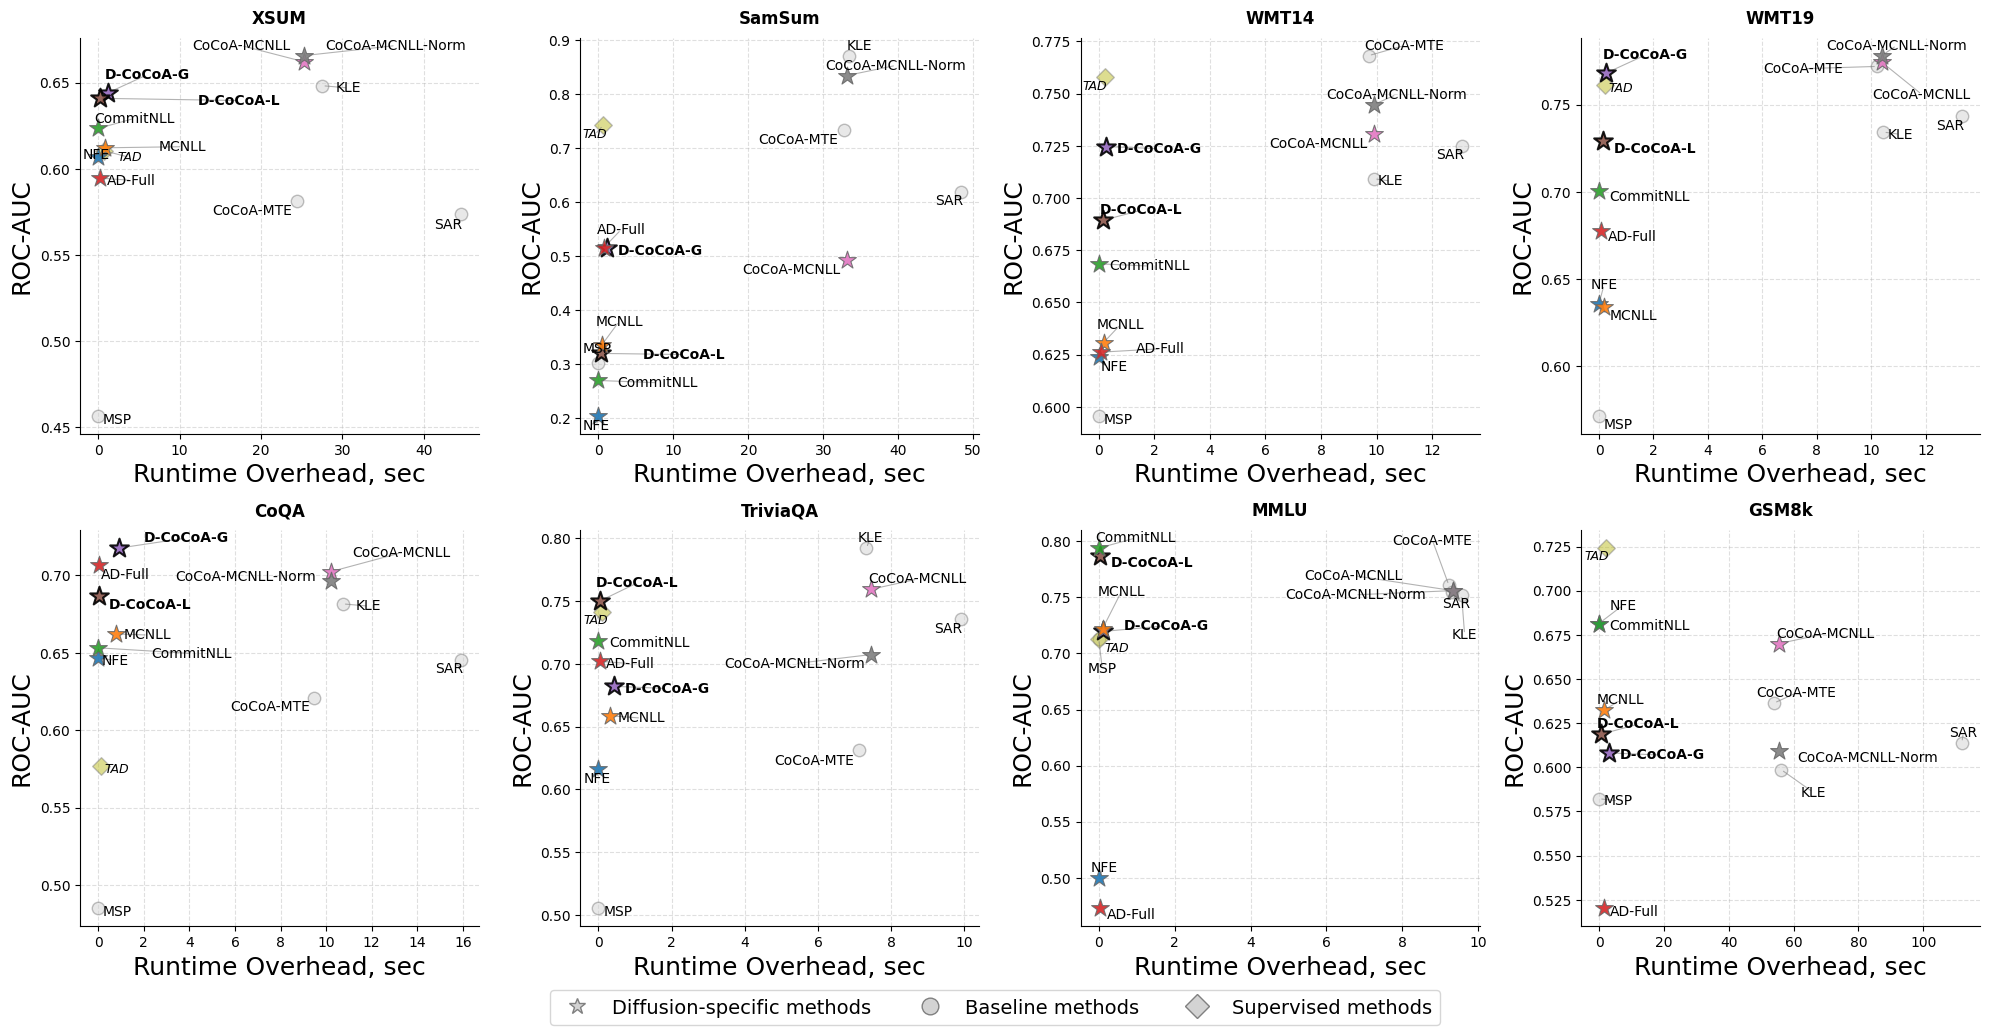

In [162]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
from adjustText import adjust_text  # <-- Импортируем библиотеку для текста
from matplotlib.lines import Line2D

# Предполагается, что методы df_all_selected и methods_time уже заданы в вашем коде выше

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
dss = list(methods_time.keys())

classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Собираем все уникальные методы, чтобы назначить каждому свой цвет навсегда
all_methods = list(methods_time[dss[0]].keys())
# Используем палитру (если методов больше 10, используйте 'tab20')
cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

# Оптимизация: делаем Method индексом один раз, чтобы быстро доставать значения
df_indexed = df_all_selected.set_index(df_all_selected.columns[0])

for i in range(2):
    for j in range(4):
        idx = i * 4 + j
        # Если датасетов меньше 8, прячем пустые графики
        if idx >= len(dss):
            axes[i, j].set_visible(False)
            continue
            
        ds = dss[idx]
        vals = methods_time[ds]
        methods = list(vals.keys())
        
        texts = []  # <-- Создаем пустой список для сбора текстовых объектов
        x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText
        
        # Строим каждую точку отдельно, чтобы гибко менять стиль
        for m in methods:
            x_val = vals[m]
            y_val = df_indexed.loc[m, ds].item() # Достаем значение по индексу
            
            x_coords.append(x_val)
            y_coords.append(y_val)
            
            # Настройки по умолчанию
            marker_style = '*'
            size = 180
            edgecolor = 'dimgray' # <-- Тёмно-серая обводка лучше выделяет слипшиеся точки
            linewidth = 0.8       # <-- Тонкая линия обводки
            z_order = 6
            alpha = 0.9
            font_weight = 'normal'
            label_text = m
            
            # Выделяем Cocoa_NFE_Trace_MC
            if m == 'D-CoCoA-G':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5         
                font_weight = 'bold'
            elif m == 'D-CoCoA-L':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5         
                font_weight = 'bold'
            # Выделяем TAD (Supervised outlier)
            elif m == 'TAD':
                marker_style = 'D'  # Ромб
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                # label_text = f"{m}\n(Supervised)" 
                edgecolor = 'gray'
                linewidth = 1.0
            elif m in classical_list:
                marker_style = 'o'  # Квадрат для классических методов
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                edgecolor = 'gray'
                linewidth = 1.0
                # font_weight = 'bold'
                
            # Рисуем точку
            axes[i, j].scatter(
                x_val, y_val, 
                s=size, 
                c=[method_colors[m]], 
                marker=marker_style, 
                edgecolors=edgecolor,
                linewidth=linewidth,
                alpha=alpha,
                zorder=z_order
            )
            
            # Создаем текст и добавляем его в список texts (ВМЕСТО annotate)
            txt = axes[i, j].text(
                x_val, y_val, label_text,
                ha='center', va='center', # Центрируем, adjustText сам их сдвинет
                fontsize=10 if m != 'TAD' else 9,
                fontweight=font_weight,
                fontstyle='italic' if m == 'TAD' else 'normal',
                zorder=11,
                # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
            )
            texts.append(txt)
            
        # <-- МАГИЯ ЗДЕСЬ: автоматически расталкиваем текст, чтобы он не перекрывал точки и друг друга
        # adjust_text(
        #     texts, 
        #     x=x_coords, # Передача координат сильно помогает алгоритму
        #     y=y_coords,
        #     ax=axes[i, j], 
        #     arrowprops=dict(arrowstyle="-", color='gray', lw=0.5, alpha=0.6),
        #     expand_points=(1.5, 1.5), 
        #     expand_text=(1.2, 1.2)    
        # )

        # adjust_text(
        #     texts, 
        #     x=x_coords,
        #     y=y_coords,
        #     ax=axes[i, j], 
        #     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),

        #     expand_points=(2.0, 2.0),   # increase distance from points
        #     expand_text=(1.8, 1.8),     # increase distance between labels

        #     force_text=(0.8, 0.8),      # stronger repulsion between texts
        #     force_points=(0.5, 0.5),    # stronger push away from points

        #     lim=200                     # more iterations → better layout
        # )

        adjust_text(
            texts, 
            x=x_coords,
            y=y_coords,
            ax=axes[i, j], 
            arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
            expand_points=(3.0, 3.0), 
            expand_text=(2.5, 2.5),
            force_points=(1.0, 1.0),
            force_text=(1.0, 1.0),
            force_explode=(0.7, 0.7),
            iterations=300,
        )

        # legend_elements = [
        #     Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
        # ]

        # axes[i, j].legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)
            
        # Эстетика подграфика
        axes[i, j].set_title(ds, fontsize=12, fontweight='bold', pad=10)
        axes[i, j].set_xlabel("Runtime Overhead, sec", fontsize=18, color='black')
        axes[i, j].set_ylabel("ROC-AUC", fontsize=18, color='black')
        
        # Красивая сетка и рамки
        axes[i, j].grid(True, linestyle='--', alpha=0.4, zorder=0)
        axes[i, j].spines['top'].set_visible(False)
        axes[i, j].spines['right'].set_visible(False)

# ВЫНОС ЛЕГЕНДЫ ВНИЗ (чтобы не перекрывала данные на 8 графиках)
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
plt.tight_layout()
fig.subplots_adjust(bottom=0.15) # Сдвигаем графики вверх
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=14, frameon=True, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig("../workdir/auroc_vs_comp.png", dpi=300, bbox_inches='tight') # Улучшено качество сохранения
plt.savefig("../workdir/auroc_vs_comp.pdf", bbox_inches='tight')
plt.show()


/tmp/ipykernel_2726786/2944019290.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


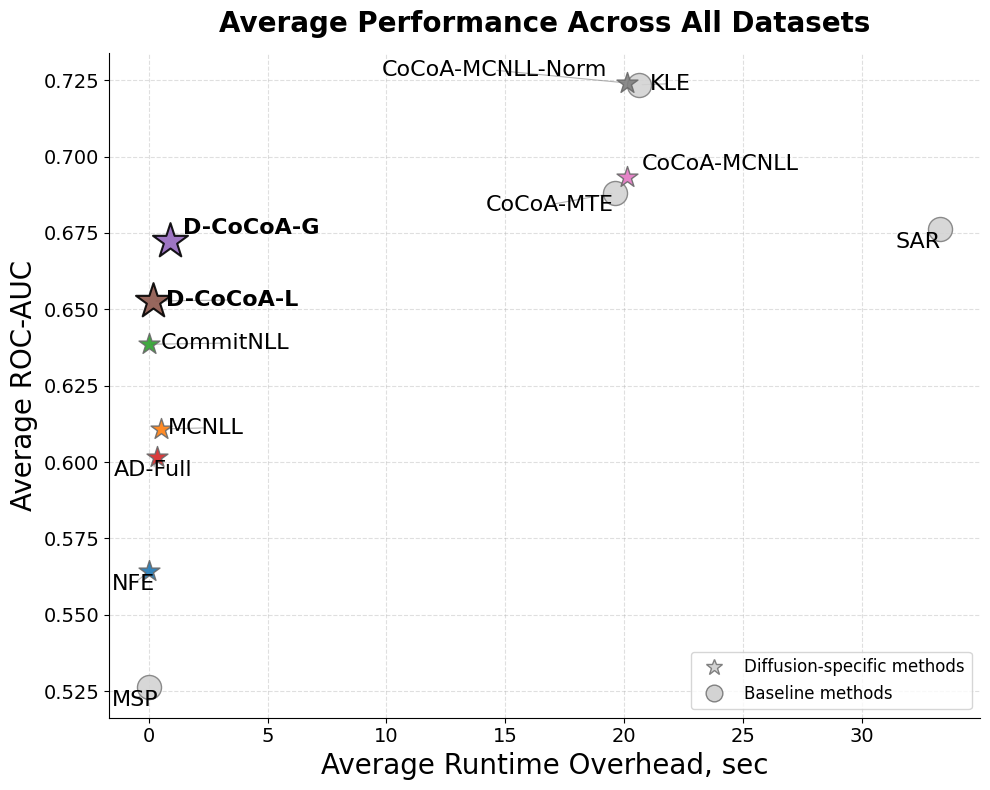

In [163]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import pandas as pd
from adjustText import adjust_text
from matplotlib.lines import Line2D

# --- 1. ПОДГОТОВКА И УСРЕДНЕНИЕ ДАННЫХ ---
dss = list(methods_time.keys())
all_methods = list(methods_time[dss[0]].keys())
df_indexed = df_all_selected.set_index(df_all_selected.columns[0])

avg_time = {}
avg_prr = {}

# --- 1. КОНФИГУРАЦИЯ ---
classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Вычисляем средние значения для каждого метода
for m in all_methods:
    # Собираем время метода m по всем датасетам и берем среднее
    times = [methods_time[ds][m] for ds in dss if m in methods_time[ds]]
    if times:
        avg_time[m] = np.mean(times)
        
    # Берем нужную строку (метод), берем столбцы датасетов и считаем среднее
    # pd.to_numeric нужен на случай, если какие-то данные считались строками
    avg_prr[m] = pd.to_numeric(df_indexed.loc[m, dss]).mean()

# --- 2. НАСТРОЙКА ОДНОГО ГРАФИКА ---
# Создаем только одну картинку, размер можно сделать поменьше, чем для сетки
fig, ax = plt.subplots(figsize=(10, 8)) 

cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

texts = []

x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText
# --- 3. ОТРИСОВКА ---
for m in all_methods:
    if m == "TAD": continue
    # Если для метода почему-то нет средних (например, пропуски в данных), пропускаем
    if m not in avg_time or m not in avg_prr or pd.isna(avg_prr[m]):
        continue
        
    x_val = avg_time[m]
    y_val = avg_prr[m]

    # x_coords.append(x_val)
    # y_coords.append(y_val)
    
    # Настройки по умолчанию (сохранены из вашего кода)
    marker_style = '*'
    size = 250            # Чуть увеличил для одиночного графика
    edgecolor = 'dimgray'
    linewidth = 1.0
    z_order = 6
    alpha = 0.9
    font_weight = 'normal'
    label_text = m
    
    # Выделяем CoCoA-NFE
    if m == 'D-CoCoA-L':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    elif m == 'D-CoCoA-G':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    # Выделяем TAD (Supervised)
    elif m == 'TAD':
        marker_style = 'D'  
        size = 180
        alpha = 0.5        
        z_order = 2        
        label_text = f"{m}\n(Supervised)" 
        edgecolor = 'gray'
        linewidth = 1.0
    elif m in classical_list:
        marker_style = 'o'  # Квадрат для классических методов
        size = 300
        edgecolor = 'black'
        linewidth = 1.2
        z_order = 4
        # font_weight = 'bold'
        edgecolor = 'gray'
        linewidth = 1.0
        
    # Рисуем точку
    ax.scatter(
        x_val, y_val, 
        s=size, 
        c=[method_colors[m]], 
        marker=marker_style, 
        edgecolors=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        zorder=z_order
    )

    if False:#m == 'D-CoCoA-L':
        pass
    # Создаем текст
    else:
        va_alignment = "center"
        ha_alignment = "center"
        text_y = y_val  # по умолчанию текст на уровне точки
        if m in ['CoCoA-MCNLL-Norm']:
            # Поднимаем текст по оси Y (значение 0.012 можно увеличить/уменьшить)
            # text_y = y_val + 0.012 
            # Якорим текст за его нижний край, чтобы он весь был НАД точкой
            va_alignment = 'bottom' 
            ha_alignment = "right"
        elif m in ['KLE']:
            va_alignment = 'top' 
            ha_alignment = "left"
        #     text_y = y_val - 0.012

        # Создаем текст
        txt = ax.text(
            x_val, text_y, label_text,
            ha=ha_alignment, va=va_alignment,
            fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
            fontweight=font_weight,
            fontstyle='italic' if m == 'TAD' else 'normal',
            zorder=11,
            # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
        )
        texts.append(txt)
        x_coords.append(x_val)
        y_coords.append(y_val)
    
    # Создаем текст
    # txt = ax.text(
    #     x_val, y_val, label_text,
    #     ha='center', va='center',
    #     fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
    #     fontweight=font_weight,
    #     fontstyle='italic' if m == 'TAD' else 'normal',
    #     zorder=11,
    #     bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
    # )
    # texts.append(txt)

# Расталкиваем текст
# adjust_text(
#     texts, 
#     x=x_coords, # Передача координат сильно помогает алгоритму
#     y=y_coords,
#     ax=ax, 
#     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
#     expand_points=(1.5, 1.5), 
#     expand_text=(1.2, 1.2)    
# )

# adjust_text(
#     texts, 
#     x=x_coords,
#     y=y_coords,
#     ax=ax, 
#     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
#     expand_points=(2.5, 2.5), 
#     expand_text=(2.0, 2.0),
#     force_points=(0.8, 0.8),
#     force_text=(0.8, 0.8),
#     force_explode=(0.5, 0.5),
# )

adjust_text(
    texts, 
    x=x_coords,
    y=y_coords,
    ax=ax, 
    arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
    expand_points=(3.0, 3.0), 
    expand_text=(2.5, 2.5),
    force_points=(1.0, 1.0),
    force_text=(1.0, 1.0),
    force_explode=(0.7, 0.7),
    iterations=300,
)
    
# --- 4. ЭСТЕТИКА ---
ax.set_title("Average Performance Across All Datasets", fontsize=20, fontweight='bold', pad=15)
ax.set_xlabel("Average Runtime Overhead, sec", fontsize=20, color='black')
ax.set_ylabel("Average ROC-AUC", fontsize=20, color='black')

# --- 5. ЛЕГЕНДА (Только по знакам) ---
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)

ax.grid(True, linestyle='--', alpha=0.4, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=14)  # increase tick label size

plt.tight_layout()

# Сохраняем с новым именем, чтобы не перезаписать файл с сеткой
plt.savefig("../workdir/avg_auroc_vs_comp.png", dpi=300, bbox_inches='tight')
plt.savefig("../workdir/avg_auroc_vs_comp.pdf", bbox_inches='tight')
plt.show()

## Dream by Vlad

In [164]:
import os
import copy
from scipy.stats import rankdata

base_path = "./workdir/output_dllm_dec25_maskedll_final"

datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['Dream']

paths = {
    "Dream": {
        "SamSum": [
            "../workdir/results/pickles/setup_c_train_only/samsum.pkl",
            "../workdir/results/pickles/cocoaL/samsum.pkl",
            "../workdir/results/pickles/setup_b_with_train/samsum copy.pkl",
            # "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
            "../workdir/results/pickles/setup_d_diffusion_merged/samsum.pkl"
        ],
        "GSM8k": [
            "../workdir/results/pickles/setup_c_train_only/gsm8k.pkl",
            "../workdir/results/pickles/cocoaL/gsm8k.pkl",
            "../workdir/results/pickles/setup_b_with_train/gsm8k copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/gsm8k.pkl"
        ],
        "CoQA": [
            "../workdir/results/pickles/setup_c_train_only/coqa.pkl",
            "../workdir/results/pickles/cocoaL/coqa.pkl",
            "../workdir/results/pickles/setup_b_with_train/coqa copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/coqa.pkl"
        ],
        "TriviaQA": [
            "../workdir/results/pickles/setup_c_train_only/triviaqa.pkl",
            "../workdir/results/pickles/cocoaL/triviaqa.pkl",
            "../workdir/results/pickles/setup_b_with_train/triviaqa copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/triviaqa.pkl"
        ],
        "MMLU": [
            "../workdir/results/pickles/setup_c_train_only/mmlu.pkl",
            "../workdir/results/pickles/cocoaL/mmlu.pkl",
            "../workdir/results/pickles/setup_b_with_train/mmlu copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/mmlu.pkl"
        ],
        "WMT14": [
            "../workdir/results/pickles/setup_b_with_train/wmt14_fren.pkl",
            "../workdir/results/pickles/cocoaL/wmt14_fren.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/wmt14_fren.pkl"
        ],
        "WMT19": [
            "../workdir/results/pickles/setup_b_with_train/wmt19_deen.pkl",
            "../workdir/results/pickles/cocoaL/wmt19_deen.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/wmt19_deen.pkl"
        ],
        "XSUM": [
            "../workdir/results/pickles/setup_c_train_only/xsum.pkl",
            "../workdir/results/pickles/setup_b_with_train/xsum copy.pkl",
            "../workdir/results/pickles/cocoaL/xsum.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/xsum.pkl"
        ],
    }
}

filename = "ue_manager_seed1"
dfs = {}

all_paths = []
for model in models:
    dfs[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        task = ds.split("/")[0]
        ds = '/'.join(ds.split("/")[1:])
        path = f"{base_path}/{task}/{model}/{ds}/"
        final_path = None
        if model in paths.keys() and ds_name in paths[model].keys():
            final_path = paths[model][ds_name]
        else:
            continue
        if final_path is not None:
            print(final_path)
            all_paths.append(final_path)
            if task == "ats":
                metric_names=['AlignScore']
            elif (ds_name in ["MMLU", "GSM8k"]):
                metric_names=["Accuracy"]
            elif task == "qa":
                metric_names=['AlignScore']
            elif task == "nmt":
                metric_names=['Comet']
            df = get_table_short(final_path, dataset=ds_name, metric_names=metric_names, ue_metric="roc_auc", level="sequence")
            dfs[model][ds_name] = df.reset_index(drop=True)

['../workdir/results/pickles/setup_c_train_only/xsum.pkl', '../workdir/results/pickles/setup_b_with_train/xsum copy.pkl', '../workdir/results/pickles/cocoaL/xsum.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/xsum.pkl']
['../workdir/results/pickles/setup_c_train_only/samsum.pkl', '../workdir/results/pickles/cocoaL/samsum.pkl', '../workdir/results/pickles/setup_b_with_train/samsum copy.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/samsum.pkl']
['../workdir/results/pickles/setup_b_with_train/wmt14_fren.pkl', '../workdir/results/pickles/cocoaL/wmt14_fren.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/wmt14_fren.pkl']
['../workdir/results/pickles/setup_b_with_train/wmt19_deen.pkl', '../workdir/results/pickles/cocoaL/wmt19_deen.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/wmt19_deen.pkl']
['../workdir/results/pickles/setup_c_train_only/coqa.pkl', '../workdir/results/pickles/cocoaL/coqa.pkl', '../workdir/results/pickles/setup_b_with_train/co

In [165]:
dfs_short = []
methods = None
model = models[0]

for key in dfs[model].keys():
    df_ = dfs[model][key]   
    if methods is None:
        methods = df_[df_.columns[-1]]
        # methods = [m for m in methods if "FullTrace" in m]
        # methods = [m for m in methods if "InverseProgress" not in m]
    df_ = df_.set_index(df_.columns[-1], drop=False).reindex(methods)
    
    if len(dfs_short):
        dfs_short.append(df_[df_.columns[[0]]])
    else:
        dfs_short.append(df_[df_.columns[[1, 0]]])
df_dream = pd.concat(dfs_short, axis=1).reset_index(drop=True)
df_dream.loc[:, ('', "Mean")] = df_dream[df_dream.columns[1:]].mean(axis=1)

In [166]:
df_dream.sort_values(df_dream.columns[-1], ascending=False).style.background_gradient(axis=0)

In [167]:
order = ['MaximumSequenceProbability', "SAR", "CocoaMTE", "KernelLanguageEntropy", "TAD", 
         "MCMaskedNLL", "NFEUncertainty",  "AvgDissimilarityFullTrace", "ConfidenceAtCommit_avg",
         "CocoaMCMaskedNLL", "CocoaMCMaskedNormalizedNLL", 
         "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace"]
order = [x for x in order if x in df_dream[df_dream.columns[0]].values]

df_dream_selected = df_dream.set_index(df_dream.columns[0]).loc[order].reset_index()
df_dream_selected[df_dream_selected.columns[0]] = df_dream_selected[df_dream_selected.columns[0]].replace({"MCMaskedNormalizedNLL": "MCNLL-Norm", "CocoaMCMaskedNormalizedNLL": "CoCoA-MCNLL-Norm", "MaximumSequenceProbability": "MSP", 
                                                                                                           "ConfidenceAtCommit_avg": "CommitNLL", "NFEUncertainty": "NFE", "MCMaskedNLL": "MCNLL", "TraceEntropy_avg": "TrajEntropy", "AvgDissimilarityFullTrace": "AD-Full", 
                                                                                                           "AvgDissimilarityFullTraceProgress": "WeightedAD-Full", "CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE": "D-CoCoA-G", "KernelLanguageEntropy": "KLE", 
                                                                                                           "DegMat_NLI_score_entail": "DegMat", "CocoaMCMaskedNLL": "CoCoA-MCNLL", "TAD": "TAD", "SAR": "SAR", "SemanticEntropy": "SemanticEntropy", "CocoaMTE": "CoCoA-MTE", 
                                                                                                           "EigenScore": "EigenScore", "LUQ": "LUQ", "CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace": "D-CoCoA-L", "TraceProbs_avg": "TrajProbs"})

df_dream_selected.columns = pd.MultiIndex.from_tuples(
    [('XSUM' if a == 'XSum' else a, b) for a, b in df_dream_selected.columns]
)

df_dream_selected.style.background_gradient(axis=0)

In [168]:
import copy

with pd.option_context("max_colwidth", 1000):
    res_str = prepare_latex(copy.deepcopy(df_dream_selected).round(2), 1).split('\n')
    res_str[2] = """\\textbf{UQ Method} & \\textbf{XSum} & \\textbf{SamSum} & \\textbf{WMT14} & \\textbf{WMT19} & \\textbf{CoQA} & \\textbf{TriviaQA} & \\textbf{MMLU} & \\textbf{GSM8k} & \\textbf{Mean} \\\\"""
    print('\n'.join(res_str))

\begin{table*}[!ht] \resizebox{\textwidth}{!}{\begin{tabular}{l|c|c|c|c|c|c|c|c|c}
\toprule
\textbf{UQ Method} & \textbf{XSum} & \textbf{SamSum} & \textbf{WMT14} & \textbf{WMT19} & \textbf{CoQA} & \textbf{TriviaQA} & \textbf{MMLU} & \textbf{GSM8k} & \textbf{Mean} \\
\midrule
MSP & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.42 & \cellcolor[rgb]{0.6449978024117646,0.6934178380941176,0.9144631795921568} 0.43 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.42 & \cellcolor[rgb]{0.6426363887647059,0.690064711317647,0.9117342756235294} 0.47 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.61 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.57 & \cellcolor[rgb]{0.9053078374137256,0.6343985308588236,0.6177138057666667} 0.86 & \cellcolor[rgb]{0.661859207627451,0.7165792202745098,0.9323611776862746} 0.59 & \cellcolor[rgb]{0.61490285,0.649358983,0.8768415764999999} 0.55 \\
SAR & \cellcolor[rgb]{0.9112102024705881,0.9284487582705883,0.955

In [169]:
def get_time(path, base=False):
    methods = {
        "MSP": ["MaximumSequenceProbability"],
        "NFE": ["NFEUncertainty"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "CommitNLL": ["ConfidenceAtCommit_avg"],
        # "TraceEntropy": ["TraceEntropy_avg"],
        "AD-Full": ["AvgDissimilarityFullTrace", "greedy_sentence_similarity_full_trace"],
        "D-CoCoA-G": ["CocoaMCMaskedNormalizedNLLCrossEncoderFullTraceNFE", "greedy_sentence_similarity_full_trace", "mc_masked_ll"],
        "D-CoCoA-L": ["CocoaConfidenceAtCommitCrossEncoderBlockAvgTrace", "greedy_sentence_similarity_block"],
        "MSP": ["MaximumSequenceProbability"],
        "MCNLL": ["MCMaskedNLL", "mc_masked_ll"],
        "KLE": ["KernelLanguageEntropy", "semantic_matrix_entail", "sample_texts"],
        # "DegMat": ["DegMat_NLI_score_entail", "semantic_matrix_entail", "sample_texts"],
        # "LUQ": ["LUQ", "semantic_matrix_entail_logits", "sample_texts"],
        "CoCoA-MTE": ["CocoaMTE", "greedy_sentence_similarity", "sample_texts"],
        # "EigenScore": ["EigenScore", "sample_embeddings"],
        "CoCoA-MCNLL": ["CocoaMCMaskedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_ll"],
        "CoCoA-MCNLL-Norm" : ["CocoaMCMaskedNormalizedNLL", "sample_texts", "greedy_sentence_similarity", "mc_masked_normalized_ll"],
        "TAD": ["TAD", "attention_features"],
        "SAR": ["SAR", "sample_sentence_similarity", "sample_texts"],
        # "SemanticEntropy": ["SemanticEntropy", "sample_texts", "semantic_matrix_entail", "semantic_classes_entail"],
    }

    times = {}
    seen_stats = {}
    
    if isinstance(path, list):
        for p in path:
            man = torch.load(p, weights_only=False)
            
            for method in methods.keys():
                for stat in methods[method]:
                    if method in seen_stats.keys() and stat in seen_stats[method]:
                        # print("seen", method, stat)
                        continue
                    if stat is None:
                        times[method] = 0
                        continue
                    if methods[method][0] not in man["time_stats"].keys():
                        # times[method] = 0
                        continue
                    elif method not in times.keys():
                        times[method] = 0
                    # print(method, stat)
                    scores = np.array(man["time_stats"][stat])
                    seen_stats[method] = seen_stats.get(method, set()).union(set([stat]))
                    if len(scores) == 0:
                        print(p, stat, scores)
                        # print(seen_stats)
                    try:
                        times[method] += np.array(scores[1:])
                    except Exception as e:
                        # print(e, len(times[method]), len(scores)) 
                        if len(times[method]) == (len(scores[1:]) - 1):
                            times[method] += np.array(scores[2:])
                        elif len(times[method]) == (len(scores[1:]) + 1):
                            times[method] += np.array([0] +scores[2:])
                        else:
                            print(p, stat, scores)
    else:
        man = torch.load(path, weights_only=False)
        
        for method in methods.keys():
            times[method] = 0
            for stat in methods[method]:
                if stat is None:
                    times[method] = 0
                    continue
                scores = np.array(man["time_stats"][stat])
                if len(scores) == 0:
                    print(stat, scores)
                times[method] += np.array(scores[1:])
    return times

In [170]:
order = ['MSP', 'NFE', 'MCNLL', 'CommitNLL', 'AD-Full', 'D-CoCoA-G', 'D-CoCoA-L', 'KLE', 'CoCoA-MTE', 'CoCoA-MCNLL', 'CoCoA-MCNLL-Norm', 'TAD', 'SAR']

In [171]:
datasets = ['ats/xsum', 'ats/samsum', "ats/['cnn_dailymail', '3.0.0']", "nmt/['wmt14', 'fr-en']", "nmt/['wmt19', 'de-en']", "qa/keivalya/MedQuad-MedicalQnADataset", "qa/['truthful_qa', 'generation']", 'qa/coqa', 'qa/sciq', "qa/['trivia_qa', 'rc.nocontext']", "qa/['cais/mmlu', 'all']", "qa/['gsm8k', 'main']"]
datasets_names = ['XSUM', 'SamSum', 'CNN', "WMT14", "WMT19", "MedQUAD", "TruthfulQA", 'CoQA', 'SciQ', "TriviaQA", "MMLU", "GSM8k"]

models = ['GSAI-ML/LLaDA-1.5/']

paths = {
    "GSAI-ML/LLaDA-1.5/": {
        "SamSum": [
            "../workdir/results/pickles/setup_c_train_only/samsum.pkl",
            "../workdir/results/pickles/cocoaL/samsum.pkl",
            "../workdir/results/pickles/setup_b_with_train/samsum copy.pkl",
            # "../workdir/dllm_baselines/ats/GSAI-ML/LLaDA-1.5/['LM-Polygraph/samsum', 'simple_instruct']/2026-03-27/01-38-57/ue_manager_seed1",
            "../workdir/results/pickles/setup_d_diffusion_merged/samsum.pkl"
        ],
        "GSM8k": [
            "../workdir/results/pickles/setup_c_train_only/gsm8k.pkl",
            "../workdir/results/pickles/cocoaL/gsm8k.pkl",
            "../workdir/results/pickles/setup_b_with_train/gsm8k copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/gsm8k.pkl"
        ],
        "CoQA": [
            "../workdir/results/pickles/setup_c_train_only/coqa.pkl",
            "../workdir/results/pickles/cocoaL/coqa.pkl",
            "../workdir/results/pickles/setup_b_with_train/coqa copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/coqa.pkl"
        ],
        "TriviaQA": [
            "../workdir/results/pickles/setup_c_train_only/triviaqa.pkl",
            "../workdir/results/pickles/cocoaL/triviaqa.pkl",
            "../workdir/results/pickles/setup_b_with_train/triviaqa copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/triviaqa.pkl"
        ],
        "MMLU": [
            "../workdir/results/pickles/setup_c_train_only/mmlu.pkl",
            "../workdir/results/pickles/cocoaL/mmlu.pkl",
            "../workdir/results/pickles/setup_b_with_train/mmlu copy.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/mmlu.pkl"
        ],
        "WMT14": [
            "../workdir/results/pickles/setup_b_with_train/wmt14_fren.pkl",
            "../workdir/results/pickles/cocoaL/wmt14_fren.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/wmt14_fren.pkl"
        ],
        "WMT19": [
            "../workdir/results/pickles/setup_b_with_train/wmt19_deen.pkl",
            "../workdir/results/pickles/cocoaL/wmt19_deen.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/wmt19_deen.pkl"
        ],
        "XSUM": [
            "../workdir/results/pickles/setup_c_train_only/xsum.pkl",
            "../workdir/results/pickles/setup_b_with_train/xsum copy.pkl",
            "../workdir/results/pickles/cocoaL/xsum.pkl",
            "../workdir/results/pickles/setup_d_diffusion_merged/xsum.pkl"
        ],
    }
}


dfs_time = {}
all_paths = []
for model in models:
    dfs_time[model] = {}
    for ds, ds_name in zip(datasets, datasets_names):
        try:
            final_path = paths[model][ds_name]
        except:
            continue
        if final_path is not None:
            print(final_path)
            df = get_time(final_path, base=False)
            dfs_time[model][ds_name] = df


['../workdir/results/pickles/setup_c_train_only/xsum.pkl', '../workdir/results/pickles/setup_b_with_train/xsum copy.pkl', '../workdir/results/pickles/cocoaL/xsum.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/xsum.pkl']
['../workdir/results/pickles/setup_c_train_only/samsum.pkl', '../workdir/results/pickles/cocoaL/samsum.pkl', '../workdir/results/pickles/setup_b_with_train/samsum copy.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/samsum.pkl']
['../workdir/results/pickles/setup_b_with_train/wmt14_fren.pkl', '../workdir/results/pickles/cocoaL/wmt14_fren.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/wmt14_fren.pkl']
['../workdir/results/pickles/setup_b_with_train/wmt19_deen.pkl', '../workdir/results/pickles/cocoaL/wmt19_deen.pkl', '../workdir/results/pickles/setup_d_diffusion_merged/wmt19_deen.pkl']
['../workdir/results/pickles/setup_c_train_only/coqa.pkl', '../workdir/results/pickles/cocoaL/coqa.pkl', '../workdir/results/pickles/setup_b_with_train/co

In [172]:
methods_time = {ds: {} for ds in dfs_time[model].keys()}
for ds in dfs_time[model]:
    for m in dfs_time[model][ds].keys():
        methods_time[ds][m] = np.mean(dfs_time[model][ds][m])

/tmp/ipykernel_2726786/3582754849.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


0 [ 0.71430082 -0.72059112]
10 [ 0.081644   -0.04468327]


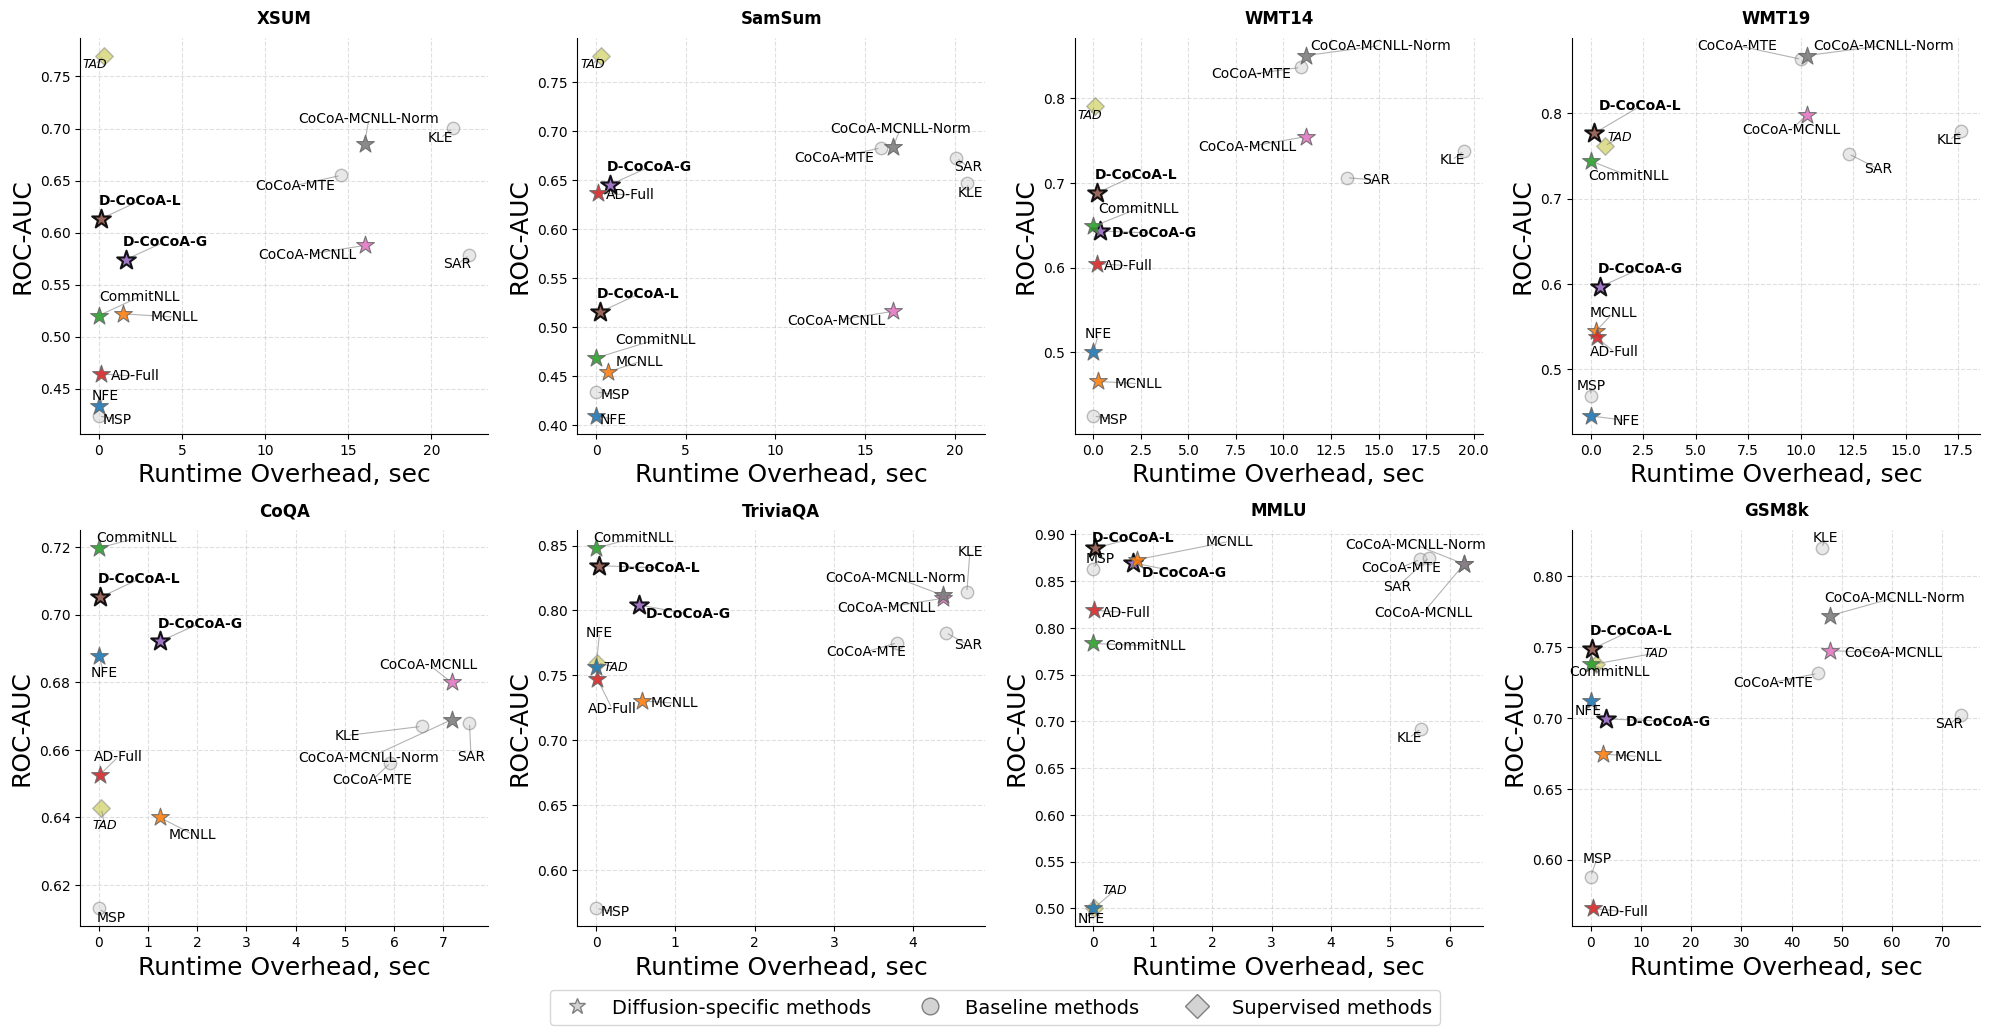

In [173]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
from adjustText import adjust_text  # <-- Импортируем библиотеку для текста
from matplotlib.lines import Line2D

# Предполагается, что методы df_dream_selected и methods_time уже заданы в вашем коде выше

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
dss = list(methods_time.keys())

classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Собираем все уникальные методы, чтобы назначить каждому свой цвет навсегда
all_methods = list(methods_time[dss[0]].keys())
# Используем палитру (если методов больше 10, используйте 'tab20')
cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in order:#all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

# Оптимизация: делаем Method индексом один раз, чтобы быстро доставать значения
df_indexed = df_dream_selected.set_index(df_dream_selected.columns[0])

for i in range(2):
    for j in range(4):
        idx = i * 4 + j
        # Если датасетов меньше 8, прячем пустые графики
        if idx >= len(dss):
            axes[i, j].set_visible(False)
            continue
            
        ds = dss[idx]
        vals = methods_time[ds]
        methods = list(vals.keys())
        
        texts = []  # <-- Создаем пустой список для сбора текстовых объектов
        x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText

        # Строим каждую точку отдельно, чтобы гибко менять стиль
        for m in methods:
            # if m == "TAD": continue
            x_val = vals[m]
            y_val = df_indexed.loc[m, ds].item() # Достаем значение по индексу

            x_coords.append(x_val)
            y_coords.append(y_val)
            
            # Настройки по умолчанию
            marker_style = '*'
            size = 180
            edgecolor = 'dimgray' # <-- Тёмно-серая обводка лучше выделяет слипшиеся точки
            linewidth = 0.8       # <-- Тонкая линия обводки
            z_order = 6
            alpha = 0.9
            font_weight = 'normal'
            label_text = m
            
            # Выделяем Cocoa_NFE_Trace_MC
            if m == 'D-CoCoA-G':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5
                # alpha = 0.5         
                font_weight = 'bold'
            elif m == 'D-CoCoA-L':
                marker_style = '*'
                size = 200          # Огромная звезда
                edgecolor = 'black' 
                linewidth = 1.5
                z_order = 5     
                # alpha = 0.5    
                font_weight = 'bold'
            # Выделяем TAD (Supervised outlier)
            elif m == 'TAD':
                marker_style = 'D'  # Ромб
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                # label_text = f"{m}\n(Supervised)" 
                edgecolor = 'gray'
                linewidth = 1.0
            elif m in classical_list:
                marker_style = 'o'  # Квадрат для классических методов
                size = 80
                alpha = 0.5        # Делаем бледным
                z_order = 2        # Уводим на задний план
                edgecolor = 'gray'
                linewidth = 1.0
                # font_weight = 'bold'
                
            # Рисуем точку
            axes[i, j].scatter(
                x_val, y_val, 
                s=size, 
                c=[method_colors[m]], 
                marker=marker_style, 
                edgecolors=edgecolor,
                linewidth=linewidth,
                alpha=alpha,
                zorder=z_order
            )

            va = "center"
            ha = "center"
            if ds == "MMLU":
                if m == "CoCoA-MCNLL":
                    # va = "bottom"
                    pass
                if m == "CoCoA-MCNLL-Norm":
                    # ha = "left"
                    va = "bottom"
            
            # Создаем текст и добавляем его в список texts (ВМЕСТО annotate)
            txt = axes[i, j].text(
                x_val, y_val, label_text,
                ha=ha, va=va, # Центрируем, adjustText сам их сдвинет
                fontsize=10 if m != 'TAD' else 9,
                fontweight=font_weight,
                fontstyle='italic' if m == 'TAD' else 'normal',
                zorder=11,
                # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
            )
            texts.append(txt)
            
        # # <-- МАГИЯ ЗДЕСЬ: автоматически расталкиваем текст, чтобы он не перекрывал точки и друг друга
        # adjust_text(
        #     texts, 
        #     x=x_coords, # Передача координат сильно помогает алгоритму
        #     y=y_coords,
        #     ax=axes[i, j], 
        #     arrowprops=dict(arrowstyle="-", color='gray', lw=0.5, alpha=0.6), # Рисует тонкие линии от текста к точке, если текст сильно сдвинулся
        #     expand_points=(1.5, 1.5), # Сила отталкивания от точек
        #     expand_text=(1.2, 1.2)    # Сила отталкивания текстов друг от друга
        # )

        # axes[i, j].set_xscale('log')

        adjust_text(
            texts, 
            x=x_coords,
            y=y_coords,
            ax=axes[i, j], 
            arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
            expand_points=(5.0, 5.0), 
            expand_text=(4.5, 4.5),
            force_points=(5.0, 5.0),
            force_text=(1.0, 1.0),
            force_explode=(2.7, 2.7),
            iterations=5000,
            min_arrow_len=0.5,
        )

        # legend_elements = [
        #     Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='gray', markersize=12),
        #     Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='gray', markersize=12),
        # ]
        # axes[i, j].legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)
            
        # Эстетика подграфика
        axes[i, j].set_title(ds, fontsize=12, fontweight='bold', pad=10)
        axes[i, j].set_xlabel("Runtime Overhead, sec", fontsize=18, color='black')
        axes[i, j].set_ylabel("ROC-AUC", fontsize=18, color='black')
        
        # Красивая сетка и рамки
        axes[i, j].grid(True, linestyle='--', alpha=0.4, zorder=0)
        axes[i, j].spines['top'].set_visible(False)
        axes[i, j].spines['right'].set_visible(False)

        # axes[i, j].set_xscale('log')


# ВЫНОС ЛЕГЕНДЫ ВНИЗ (чтобы не перекрывала данные на 8 графиках)
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='D', color='w', label='Supervised methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
plt.tight_layout()
fig.subplots_adjust(bottom=0.15) # Сдвигаем графики вверх
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=14, frameon=True, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig("../workdir/dream_auroc_vs_comp.png", dpi=300, bbox_inches='tight') # Улучшено качество сохранения
plt.savefig("../workdir/dream_auroc_vs_comp.pdf", bbox_inches='tight')
plt.show()


/tmp/ipykernel_2726786/1835834246.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')


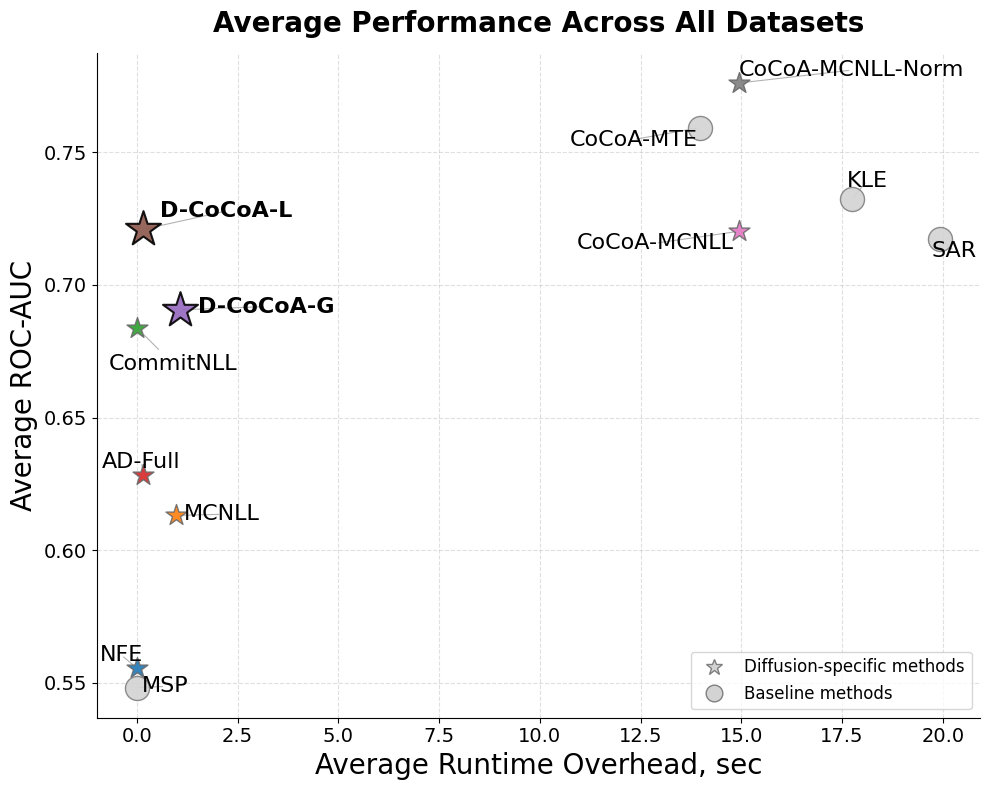

In [174]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import pandas as pd
from adjustText import adjust_text
from matplotlib.lines import Line2D

# --- 1. ПОДГОТОВКА И УСРЕДНЕНИЕ ДАННЫХ ---
dss = list(methods_time.keys())
all_methods = list(methods_time[dss[0]].keys())
df_indexed = df_dream_selected.set_index(df_dream_selected.columns[0])

avg_time = {}
avg_prr = {}

# --- 1. КОНФИГУРАЦИЯ ---
classical_list = ['KLE', 'SAR', 'CoCoA-MTE', 'MSP']

# Вычисляем средние значения для каждого метода
for m in order:
    # if m == "TAD": continue
    # Собираем время метода m по всем датасетам и берем среднее
    times = [methods_time[ds][m] for ds in dss if m in methods_time[ds]]
    if times:
        avg_time[m] = np.mean(times)
        
    # Берем нужную строку (метод), берем столбцы датасетов и считаем среднее
    # pd.to_numeric нужен на случай, если какие-то данные считались строками
    avg_prr[m] = pd.to_numeric(df_indexed.loc[m, dss]).mean()

# --- 2. НАСТРОЙКА ОДНОГО ГРАФИКА ---
# Создаем только одну картинку, размер можно сделать поменьше, чем для сетки
fig, ax = plt.subplots(figsize=(10, 8)) 

cmap = cm.get_cmap('tab10' if (len(all_methods) - len(classical_list)) <= 10 else 'Set3')

method_colors = {}
j = 0
for m in order:#all_methods:
    if m in classical_list:
        method_colors[m] = 'lightgray'  # Серый цвет для классических методов
    else:
        method_colors[m] = cmap(j)  # Цвет из палитры для остальных методов
        j+=1

# method_colors = {m: cmap(i) for i, m in enumerate(all_methods)}

texts = []

x_coords, y_coords = [], [] # Списки координат для лучшей работы adjustText
# --- 3. ОТРИСОВКА ---
for m in order:#all_methods:
    if m == "TAD": continue
    # Если для метода почему-то нет средних (например, пропуски в данных), пропускаем
    if m not in avg_time or m not in avg_prr or pd.isna(avg_prr[m]):
        continue
        
    # x_coords.append(x_val)
    # y_coords.append(y_val)
    x_val = avg_time[m]
    y_val = avg_prr[m]
    
    # Настройки по умолчанию (сохранены из вашего кода)
    marker_style = '*'
    size = 250            # Чуть увеличил для одиночного графика
    edgecolor = 'dimgray'
    linewidth = 1.0
    z_order = 6
    alpha = 0.9
    font_weight = 'normal'
    label_text = m
    
    # Выделяем CoCoA-NFE
    if m == 'D-CoCoA-L':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    elif m == 'D-CoCoA-G':
        marker_style = '*'
        size = 700          # Огромная звезда
        edgecolor = 'black' 
        linewidth = 1.5
        z_order = 5         
        font_weight = 'bold'
    # Выделяем TAD (Supervised)
    elif m == 'TAD':
        marker_style = 'D'  
        size = 180
        alpha = 0.5        
        z_order = 2        
        label_text = f"{m}\n(Supervised)" 
        edgecolor = 'gray'
        linewidth = 1.0
    elif m in classical_list:
        marker_style = 'o'  # Квадрат для классических методов
        size = 300
        edgecolor = 'black'
        linewidth = 1.2
        z_order = 4
        # font_weight = 'bold'
        edgecolor = 'gray'
        linewidth = 1.0
        
    # Рисуем точку
    ax.scatter(
        x_val, y_val, 
        s=size, 
        c=[method_colors[m]], 
        marker=marker_style, 
        edgecolors=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        zorder=z_order
    )
    
    if m == 'CommitNLL':
        pass
    # Создаем текст
    else:
        va_alignment = "center"
        ha_alignment = "center"
        text_y = y_val  # по умолчанию текст на уровне точки
        if m in ['D-CoCoA-G', 'D-CoCoA-L', 'KLE']:
            # Поднимаем текст по оси Y (значение 0.012 можно увеличить/уменьшить)
            # text_y = y_val + 0.012 
            # Якорим текст за его нижний край, чтобы он весь был НАД точкой
            va_alignment = 'bottom' 
            ha_alignment = "left"
        elif m in ['CommitNLL']:
            va_alignment = 'top' 
            ha_alignment = "right"
        #     text_y = y_val - 0.012

        # Создаем текст
        txt = ax.text(
            x_val, text_y, label_text,
            ha=ha_alignment, va=va_alignment,
            fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
            fontweight=font_weight,
            fontstyle='italic' if m == 'TAD' else 'normal',
            zorder=11,
            # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
        )
        texts.append(txt)
        x_coords.append(x_val)
        y_coords.append(y_val)
        # txt = ax.text(
        #     x_val, y_val, label_text,
        #     ha='center', va='center',
        #     fontsize=16 if m != 'TAD' else 10, # Шрифт чуть больше для одиночной картинки
        #     fontweight=font_weight,
        #     fontstyle='italic' if m == 'TAD' else 'normal',
        #     zorder=11,
        #     # bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7) 
        # )
        # texts.append(txt)

# Расталкиваем текст
# adjust_text(
#     texts, 
#     x=x_coords, # Передача координат сильно помогает алгоритму
#     y=y_coords,
#     ax=ax, 
#     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
#     expand_points=(1.5, 1.5), 
#     expand_text=(1.2, 1.2)    
# )

adjust_text(
    texts, 
    x=x_coords,
    y=y_coords,
    ax=ax, 
    arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6), 
    expand_points=(3.0, 3.0), 
    expand_text=(2.5, 2.5),
    force_points=(1.0, 1.0),
    force_text=(1.0, 1.0),
    force_explode=(0.7, 0.7),
    iterations=300,
)

ax.annotate(
    'CommitNLL',
    xy=(avg_time['CommitNLL'], avg_prr['CommitNLL']),  # конец стрелки — точка данных
    xytext=(avg_time['CommitNLL'] + 2.5, avg_prr['CommitNLL'] - 0.01),  # позиция текста
    ha='right', va='top',
    fontsize=16,
    arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),
    zorder=11,
)

# ax.annotate(
#     'D-CoCoA-L',
#     xy=(avg_time['D-CoCoA-L'], avg_prr['D-CoCoA-L']),  # конец стрелки — точка данных
#     xytext=(avg_time['D-CoCoA-L'], avg_prr['D-CoCoA-L']),  # позиция текста
#     ha='right', va='top',
#     fontsize=16,
#     arrowprops=dict(arrowstyle="-", color='gray', lw=0.8, alpha=0.6),
#     zorder=11,
# )
    
# --- 4. ЭСТЕТИКА ---
ax.set_title("Average Performance Across All Datasets", fontsize=20, fontweight='bold', pad=15)
ax.set_xlabel("Average Runtime Overhead, sec", fontsize=20, color='black')
ax.set_ylabel("Average ROC-AUC", fontsize=20, color='black')

# --- 5. ЛЕГЕНДА (Только по знакам) ---
legend_elements = [
    Line2D([0], [0], marker='*', color='w', label='Diffusion-specific methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Baseline methods', markerfacecolor='lightgray', markeredgecolor='gray', markersize=12),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True)

ax.grid(True, linestyle='--', alpha=0.4, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=14)  # increase tick label size

plt.tight_layout()

# Сохраняем с новым именем, чтобы не перезаписать файл с сеткой
plt.savefig("../workdir/dream_avg_auroc_vs_comp.png", dpi=300, bbox_inches='tight')
plt.savefig("../workdir/dream_avg_auroc_vs_comp.pdf", bbox_inches='tight')
plt.show()